# Panorama dos resumos digitais — Eleições 2026

Os arquivos `extracted/*/*.html` listam **nomes de arquivos e seus hashes publicados**, não votos, candidatos ou apuração. Este notebook lê os HTMLs locais (inclusive as duas datas das mídias), desconsidera `__MACOSX` e separa registros de arquivo de linhas `HASH GERAL` e cabeçalhos de seção.

Execute as células em ordem. Os gráficos e as tabelas já estão salvos neste `.ipynb`: ao executar novamente com `python test/run_notebooks.py`, os PNGs continuam embutidos no notebook salvo.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt

# Funciona tanto no diretório do notebook (test/) quanto na raiz do projeto.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "extracted").is_dir() and (p / "test" / "manifestos.py").is_file()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError("Abra este notebook na raiz do repositório ou em test/.")
sys.path.insert(0, str(RAIZ / "test"))
from manifestos import load_manifests, is_sha512_base64
from notebook_utils import show_table

manifestos = load_manifests(RAIZ)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print(f"Fonte: extracted/ — {len(manifestos)} manifestos HTML")

Fonte: extracted/ — 32 manifestos HTML


## Quantos arquivos aparecem em cada grupo?
As contagens são linhas de manifestos, **não** números de arquivos verificados nem votos. O mesmo arquivo pode constar em vários manifestos.

In [2]:
nomes = {
    "urnas": "Urnas (4 modelos)",
    "sistemas_itnm": "Sistemas ITNM",
    "sistemas_pc": "Sistemas PC",
    "midias": "Mídias de verificação",
}
linhas = []
for familia, nome in nomes.items():
    grupo = [m for m in manifestos if m.family == familia]
    linhas.append((
        nome, len(grupo),
        sum(e.kind == "file" for m in grupo for e in m.entries),
        sum(e.kind == "aggregate" for m in grupo for e in m.entries),
    ))
show_table(["Grupo", "Manifestos", "Linhas de arquivo", "Hashes gerais"], linhas)

Grupo,Manifestos,Linhas de arquivo,Hashes gerais
Urnas (4 modelos),4,2455,112
Sistemas ITNM,12,254,2
Sistemas PC,8,462,8
Mídias de verificação,8,60,0


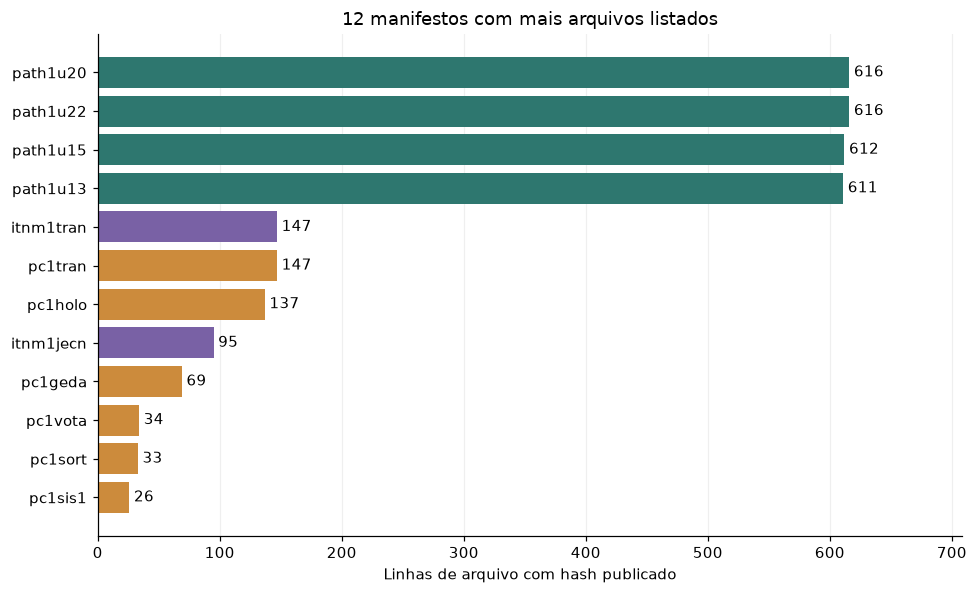

In [3]:
maiores = sorted(
    manifestos,
    key=lambda m: sum(e.kind == "file" for e in m.entries),
    reverse=True,
)[:12]
maiores.reverse()
valores = [sum(e.kind == "file" for e in m.entries) for m in maiores]
cores = {
    "urnas": "#2e776f", "sistemas_itnm": "#7961a5",
    "sistemas_pc": "#cc8b3c", "midias": "#517aab",
}
fig, ax = plt.subplots(figsize=(9, 5.5))
barras = ax.barh(
    [m.source.parent.name for m in maiores], valores,
    color=[cores.get(m.family, "#888888") for m in maiores],
)
ax.bar_label(barras, padding=3)
ax.set_xlim(0, max(valores) * 1.15)
ax.set_xlabel("Linhas de arquivo com hash publicado")
ax.set_title("12 manifestos com mais arquivos listados")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## Formato e pesquisa
A checagem abaixo apenas decodifica Base64 e verifica o tamanho esperado de um SHA-512 (64 bytes). **Não verifica os arquivos originais, as assinaturas nem a autenticidade dos hashes.**

In [4]:
entradas = [(m, e) for m in manifestos for e in m.entries]
invalidos = [(m, e) for m, e in entradas if not is_sha512_base64(e.digest)]
print(f"{len(entradas)} valores de hash; {len(invalidos)} fora do formato Base64 de 64 bytes.")
if invalidos:
    show_table(["Manifesto", "Arquivo", "Hash"],
               ((str(m.source), e.path, e.digest) for m, e in invalidos[:10]))

3353 valores de hash; 0 fora do formato Base64 de 64 bytes.


Edite `GRUPO` e `BUSCA`, depois execute as duas células seguintes para localizar caminhos ou nomes de sistemas. A tabela mostra o hash completo e limita apenas a **exibição**, não a contagem.

In [5]:
GRUPO = "todos"  # todos | urnas | sistemas_itnm | sistemas_pc | midias
BUSCA = "versoes.properties"  # trecho do caminho OU do subtítulo do manifesto
MAX_RESULTADOS = 12

In [6]:
if GRUPO not in {"todos", *nomes}:
    raise ValueError(f"Grupo desconhecido: {GRUPO!r}")
resultados = [
    (m, e) for m, e in entradas
    if (GRUPO == "todos" or m.family == GRUPO)
    and BUSCA.casefold() in f"{e.path} {m.subtitle}".casefold()
]
print(f"{len(resultados)} registros encontrados; mostrando até {MAX_RESULTADOS}.")
show_table(
    ["Manifesto", "Tipo", "Arquivo / resumo geral", "SHA-512 (Base64)"],
    ((str(m.source), e.kind, e.path, e.digest)
     for m, e in resultados[:MAX_RESULTADOS]),
)

7 registros encontrados; mostrando até 12.


Manifesto,Tipo,Arquivo / resumo geral,SHA-512 (Base64)
extracted/path1u13/path1u13.html,file,/etc/versoes.properties,aGN9HJl4/rSW3piRpoTaiePIxljD9G2zhA+V9TLq5ry1F0ruCyM/fix9NYCuzja7lIfX/N51iRYv/HRzlFFFMA==
extracted/path1u15/path1u15.html,file,/etc/versoes.properties,aGN9HJl4/rSW3piRpoTaiePIxljD9G2zhA+V9TLq5ry1F0ruCyM/fix9NYCuzja7lIfX/N51iRYv/HRzlFFFMA==
extracted/path1u20/path1u20.html,file,/etc/versoes.properties,aGN9HJl4/rSW3piRpoTaiePIxljD9G2zhA+V9TLq5ry1F0ruCyM/fix9NYCuzja7lIfX/N51iRYv/HRzlFFFMA==
extracted/path1u22/path1u22.html,file,/etc/versoes.properties,aGN9HJl4/rSW3piRpoTaiePIxljD9G2zhA+V9TLq5ry1F0ruCyM/fix9NYCuzja7lIfX/N51iRYv/HRzlFFFMA==
extracted/pc1geda/pc1geda.html,file,D:\Aplic\SEVIN\GEDAIUE\aplic\versoes.properties,aGN9HJl4/rSW3piRpoTaiePIxljD9G2zhA+V9TLq5ry1F0ruCyM/fix9NYCuzja7lIfX/N51iRYv/HRzlFFFMA==
extracted/pc1sort/pc1sort.html,file,D:\Aplic\SEVIN\Sorteio\aplic\versoes.properties,aGN9HJl4/rSW3piRpoTaiePIxljD9G2zhA+V9TLq5ry1F0ruCyM/fix9NYCuzja7lIfX/N51iRYv/HRzlFFFMA==
extracted/pc1vota/pc1vota.html,file,D:\Aplic\SEVIN\Votacao\aplic\versoes.properties,aGN9HJl4/rSW3piRpoTaiePIxljD9G2zhA+V9TLq5ry1F0ruCyM/fix9NYCuzja7lIfX/N51iRYv/HRzlFFFMA==
